# Predicting Credit Card Fraud
## Score: .95067

## EDA


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from scipy import sparse as sp
from xgboost import XGBClassifier
from catboost import CatBoostClassifier, Pool
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder

train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")
sample_submission = pd.read_csv("data/sample_submission.csv")
y = train["is_fraud"].astype(int)

cat_cols = ["merchant_category", "card_type", "auth_method", "channel", "device_type"]
bool_cols = [
    "is_foreign_transaction",
    "is_new_merchant",
    "used_vpn",
    "ip_country_mismatch",
    "billing_shipping_mismatch",
    "is_ai_generated_scam_attempt",
]
num_cols = [
    c
    for c in train.columns
    if c not in cat_cols + bool_cols + ["id", "is_fraud"]
]
digit_num_cols = [
    "amount_usd",
    "hours_since_last_txn",
    "distance_from_home_km",
    "account_balance_usd",
    "velocity_score",
    "merchant_risk_score",
]

In [2]:
display(pd.DataFrame({
    "split": ["train", "test"],
    "rows": [len(train), len(test)],
    "cols": [train.shape[1], test.shape[1]],
    "nulls": [train.isna().sum().sum(), test.isna().sum().sum()],
    "dup_ids": [train["id"].duplicated().sum(), test["id"].duplicated().sum()],
}))
display(train.dtypes.to_frame("dtype"))
display(train[num_cols + ["is_fraud"]].describe().T)

,split,rows,cols,nulls,dup_ids
0,train,699960,26,0,0
1,test,299984,25,0,0


,dtype
id,int64
amount_usd,float64
hours_since_last_txn,float64
txn_count_last_24h,int64
distance_from_home_km,float64
card_age_months,int64
customer_age,int64
account_balance_usd,float64
cvv_retry_count,int64
velocity_score,float64


,count,mean,std,min,25%,50%,75%,max
amount_usd,699960.0,79.893068,205.173538,1.00,15.81,27.25,43.11,6872.69
hours_since_last_txn,699960.0,6.633734,6.290133,0.01,2.11,4.73,9.19,51.98
txn_count_last_24h,699960.0,2.984092,1.498998,0.00,2.00,3.00,4.00,11.00
distance_from_home_km,699960.0,13.587575,11.617325,0.00,4.43,10.22,19.75,57.93
card_age_months,699960.0,46.862982,5.579190,25.00,43.00,47.00,51.00,73.00
customer_age,699960.0,51.430286,17.899150,18.00,38.00,52.00,66.00,81.00
account_balance_usd,699960.0,2064.998070,3400.132922,58.25,834.12,1382.74,2517.02,99701.39
cvv_retry_count,699960.0,0.085472,0.289524,0.00,0.00,0.00,0.00,3.00
velocity_score,699960.0,18.929445,10.864385,0.00,11.40,18.60,26.00,72.90
time_of_day_hour,699960.0,11.761915,6.869164,0.00,6.00,12.00,18.00,23.00


,count,rate
is_fraud,,
0.0,688271,0.9833
1.0,11689,0.0167


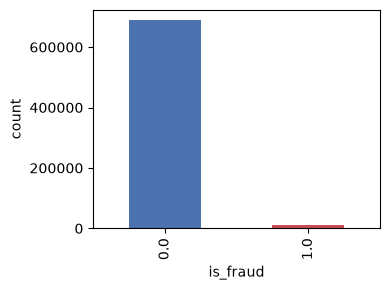

In [3]:
target_counts = train["is_fraud"].value_counts().rename("count")
target_rate = train["is_fraud"].value_counts(normalize=True).rename("rate")
display(pd.concat([target_counts, target_rate], axis=1))

fig, ax = plt.subplots(figsize=(4, 3))
train["is_fraud"].value_counts().plot(kind="bar", ax=ax, color=["#4C72B0", "#C44E52"])
ax.set_xlabel("is_fraud")
ax.set_ylabel("count")
plt.tight_layout()
plt.show()

,feature,fraud_rate,count
merchant_category,,,
Gift Cards,merchant_category,0.072970,9456
Crypto Exchange,merchant_category,0.065279,5285
Gaming,merchant_category,0.055121,23784
Electronics,merchant_category,0.030826,48693
Streaming,merchant_category,0.022481,47196
Travel,merchant_category,0.018597,28715
Utilities,merchant_category,0.013824,42027
Healthcare,merchant_category,0.012873,35889
Fuel,merchant_category,0.012375,59880


,feature,fraud_rate,count
card_type,,,
Amex,card_type,0.019019,45797
Visa,card_type,0.016985,345001
RuPay,card_type,0.016806,37070
Mastercard,card_type,0.016025,254857
Discover,card_type,0.014563,17235


,feature,fraud_rate,count
auth_method,,,
No Authentication,auth_method,0.064450,67060
3D Secure,auth_method,0.014750,210036
OTP,auth_method,0.014066,175178
PIN,auth_method,0.008681,154020
Biometric,auth_method,0.004996,93666


,feature,fraud_rate,count
channel,,,
Online,channel,0.017424,273939
POS,channel,0.016603,206465
In-App,channel,0.016329,83716
ATM,channel,0.015884,30220
Contactless,channel,0.015537,105620


,feature,fraud_rate,count
device_type,,,
POS Terminal,device_type,0.017291,113237
iPhone,device_type,0.017220,164691
Mac,device_type,0.017102,33973
Tablet,device_type,0.017011,27688
Smart Watch,device_type,0.017009,21106
ATM Machine,device_type,0.016956,20877
Windows PC,device_type,0.016137,80934
Android Phone,device_type,0.016104,237454


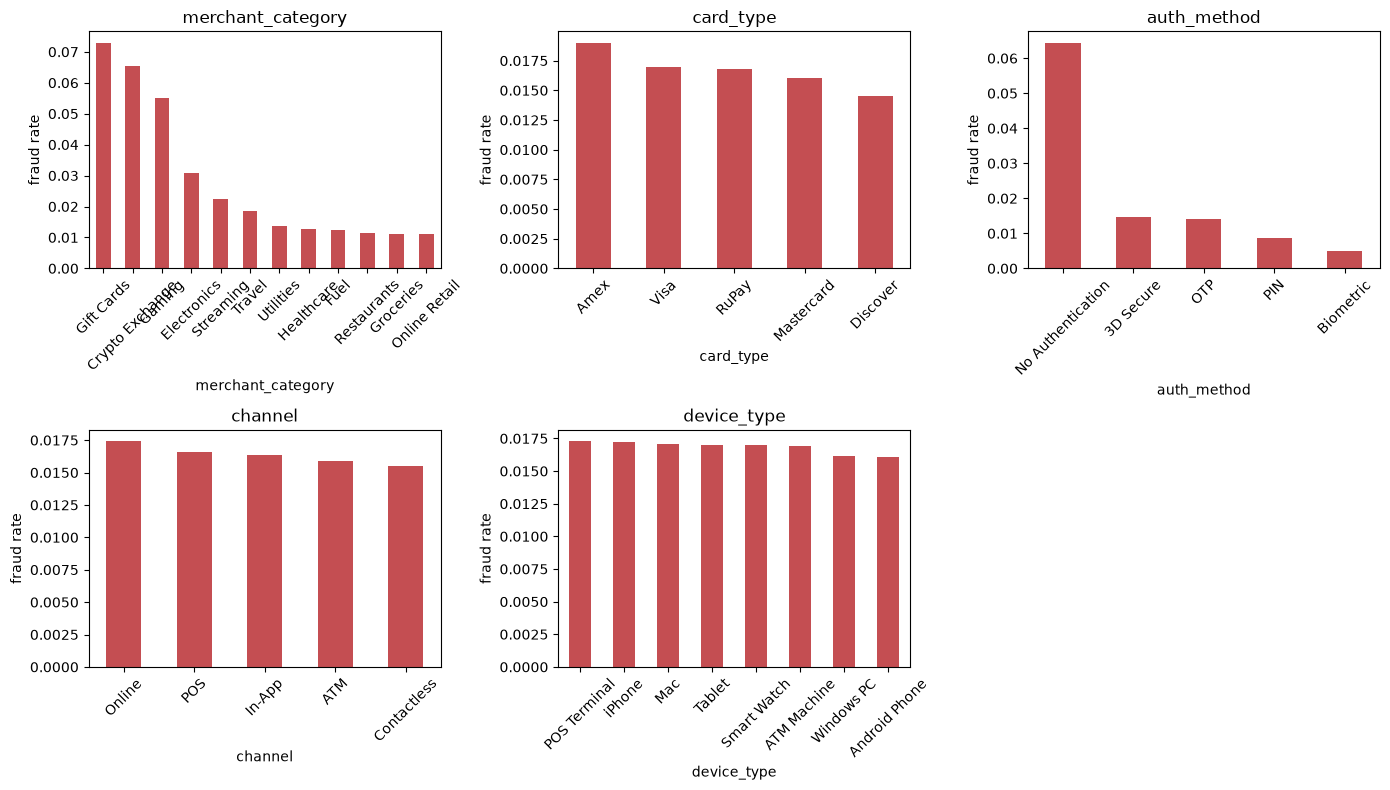

In [4]:
fraud_by_cat = []
for col in cat_cols:
    g = (
        train.groupby(col)["is_fraud"]
        .agg(fraud_rate="mean", count="size")
        .sort_values("fraud_rate", ascending=False)
    )
    g.insert(0, "feature", col)
    fraud_by_cat.append(g)
    display(g)

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.ravel()
for i, col in enumerate(cat_cols):
    rates = train.groupby(col)["is_fraud"].mean().sort_values(ascending=False)
    rates.plot(kind="bar", ax=axes[i], color="#C44E52")
    axes[i].set_title(col)
    axes[i].set_ylabel("fraud rate")
    axes[i].tick_params(axis="x", rotation=45)
axes[-1].axis("off")
plt.tight_layout()
plt.show()

,feature,fraud_rate,count
False,is_foreign_transaction,0.014782,687862
True,is_foreign_transaction,0.125723,12098
False,is_new_merchant,0.011188,593240
True,is_new_merchant,0.047339,106720
False,used_vpn,0.014992,676295
True,used_vpn,0.065498,23665
False,ip_country_mismatch,0.014264,688648
True,ip_country_mismatch,0.164958,11312
False,billing_shipping_mismatch,0.015216,690906
True,billing_shipping_mismatch,0.129887,9054


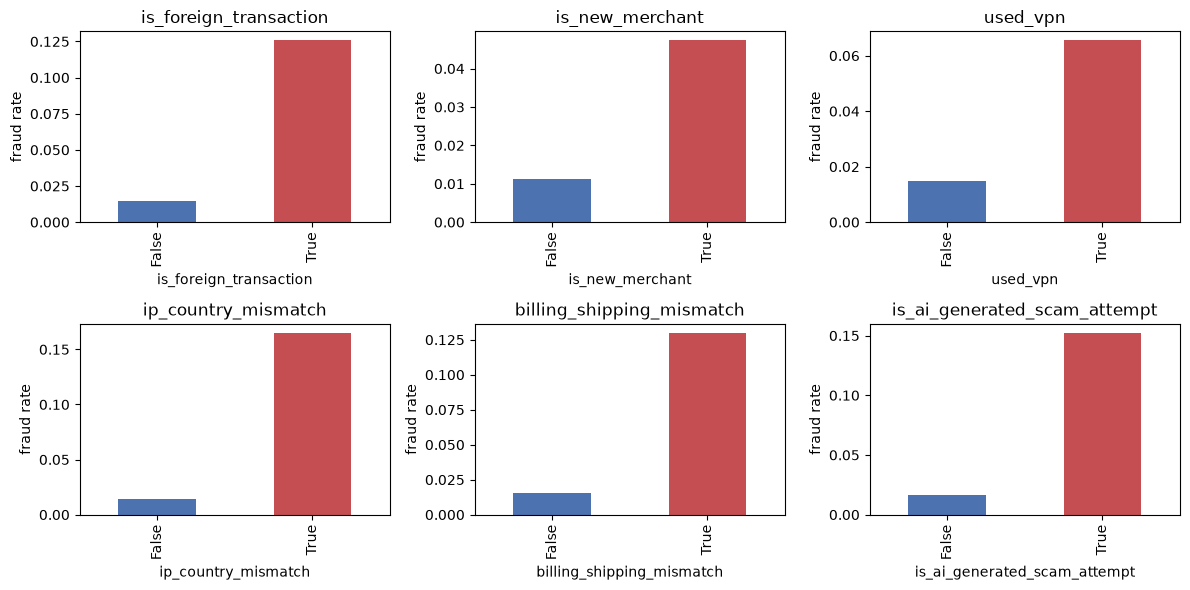

In [5]:
bool_stats = []
for col in bool_cols:
    g = train.groupby(col)["is_fraud"].agg(fraud_rate="mean", count="size")
    g.insert(0, "feature", col)
    bool_stats.append(g)
display(pd.concat(bool_stats))

fig, axes = plt.subplots(2, 3, figsize=(12, 6))
axes = axes.ravel()
for i, col in enumerate(bool_cols):
    rates = train.groupby(col)["is_fraud"].mean()
    rates.plot(kind="bar", ax=axes[i], color=["#4C72B0", "#C44E52"])
    axes[i].set_title(col)
    axes[i].set_ylabel("fraud rate")
plt.tight_layout()
plt.show()

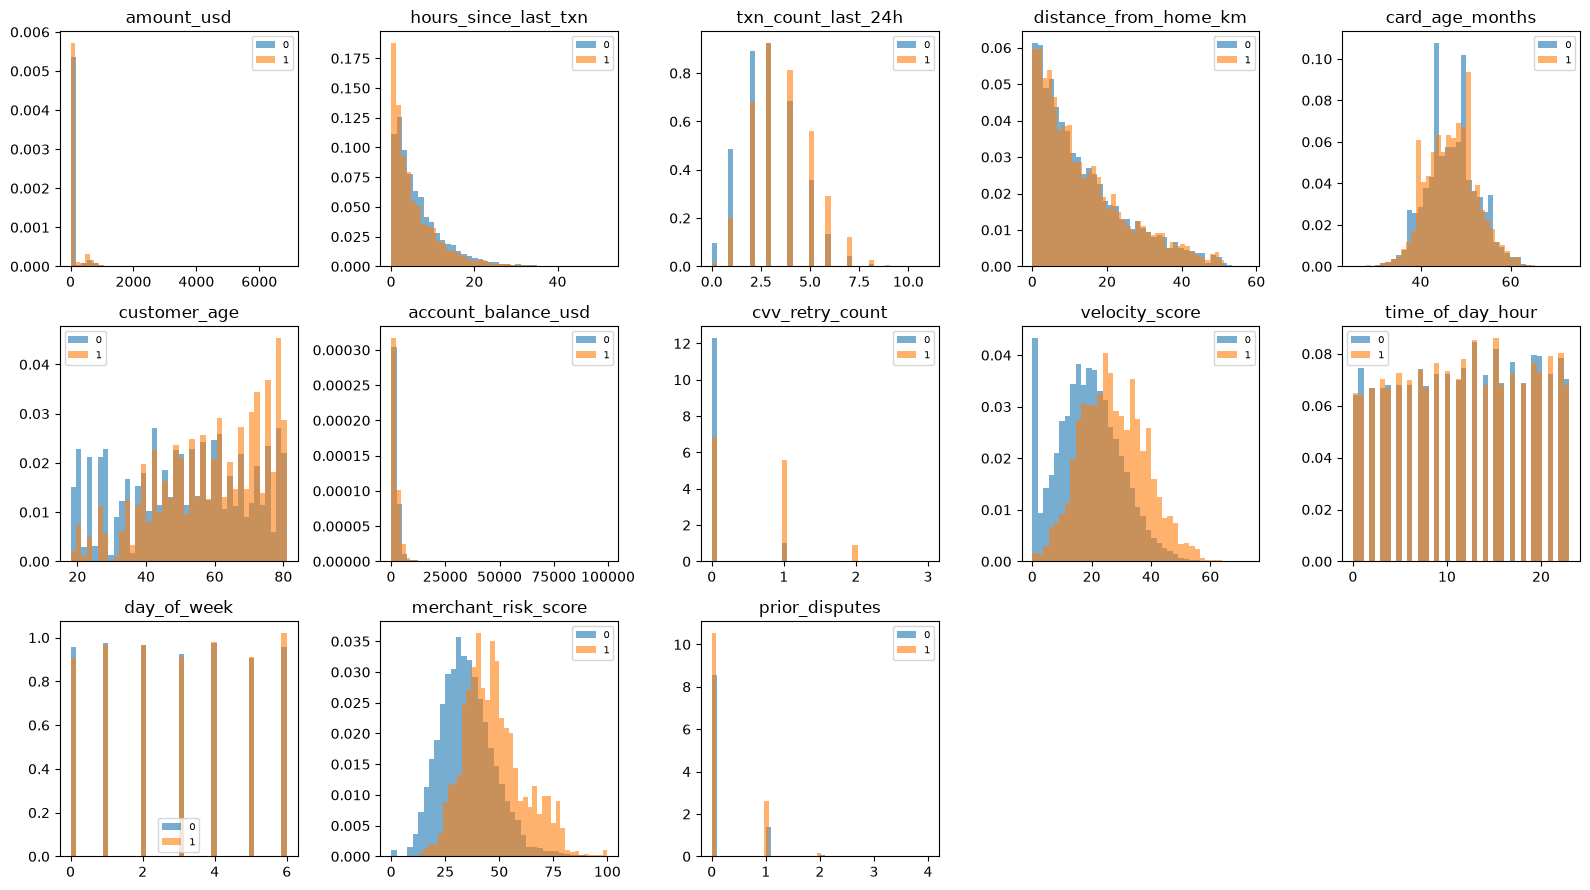

is_fraud,legit,fraud
cvv_retry_count,,
0,0.990671,0.009329
1,0.912499,0.087501
2,0.582677,0.417323
3,0.640000,0.360000


In [6]:
fig, axes = plt.subplots(3, 5, figsize=(16, 9))
axes = axes.ravel()
for i, col in enumerate(num_cols):
    axes[i].hist(train.loc[train["is_fraud"] == 0, col], bins=40, alpha=0.6, density=True, label="0")
    axes[i].hist(train.loc[train["is_fraud"] == 1, col], bins=40, alpha=0.6, density=True, label="1")
    axes[i].set_title(col)
    axes[i].legend(fontsize=7)
for j in range(len(num_cols), len(axes)):
    axes[j].axis("off")
plt.tight_layout()
plt.show()

display(
    pd.crosstab(train["cvv_retry_count"], train["is_fraud"], normalize="index")
    .rename(columns={0.0: "legit", 1.0: "fraud"})
)

In [7]:
shift_rows = []
for col in num_cols + bool_cols:
    shift_rows.append({
        "feature": col,
        "train_mean": train[col].astype(float).mean(),
        "test_mean": test[col].astype(float).mean(),
    })
shift = pd.DataFrame(shift_rows)
shift["rel_diff_pct"] = (
    (shift["test_mean"] - shift["train_mean"]) / (shift["train_mean"].abs() + 1e-9) * 100
)
display(shift.sort_values("rel_diff_pct", key=np.abs, ascending=False))

,feature,train_mean,test_mean,rel_diff_pct
18,is_ai_generated_scam_attempt,0.003284,0.003430,4.436312
15,used_vpn,0.033809,0.032968,-2.486462
17,billing_shipping_mismatch,0.012935,0.013087,1.177731
16,ip_country_mismatch,0.016161,0.016034,-0.784206
12,prior_disputes,0.152769,0.153922,0.754613
13,is_foreign_transaction,0.017284,0.017394,0.638841
10,day_of_week,2.981733,2.971338,-0.348615
6,account_balance_usd,2064.998070,2071.467998,0.313314
14,is_new_merchant,0.152466,0.152828,0.237624
9,time_of_day_hour,11.761915,11.746940,-0.127319


,corr_with_is_fraud
cvv_retry_count,0.212290
ip_country_mismatch,0.148284
merchant_risk_score,0.125391
is_foreign_transaction,0.112832
velocity_score,0.101650
is_new_merchant,0.101412
billing_shipping_mismatch,0.101115
used_vpn,0.071235
is_ai_generated_scam_attempt,0.060719
txn_count_last_24h,0.058035


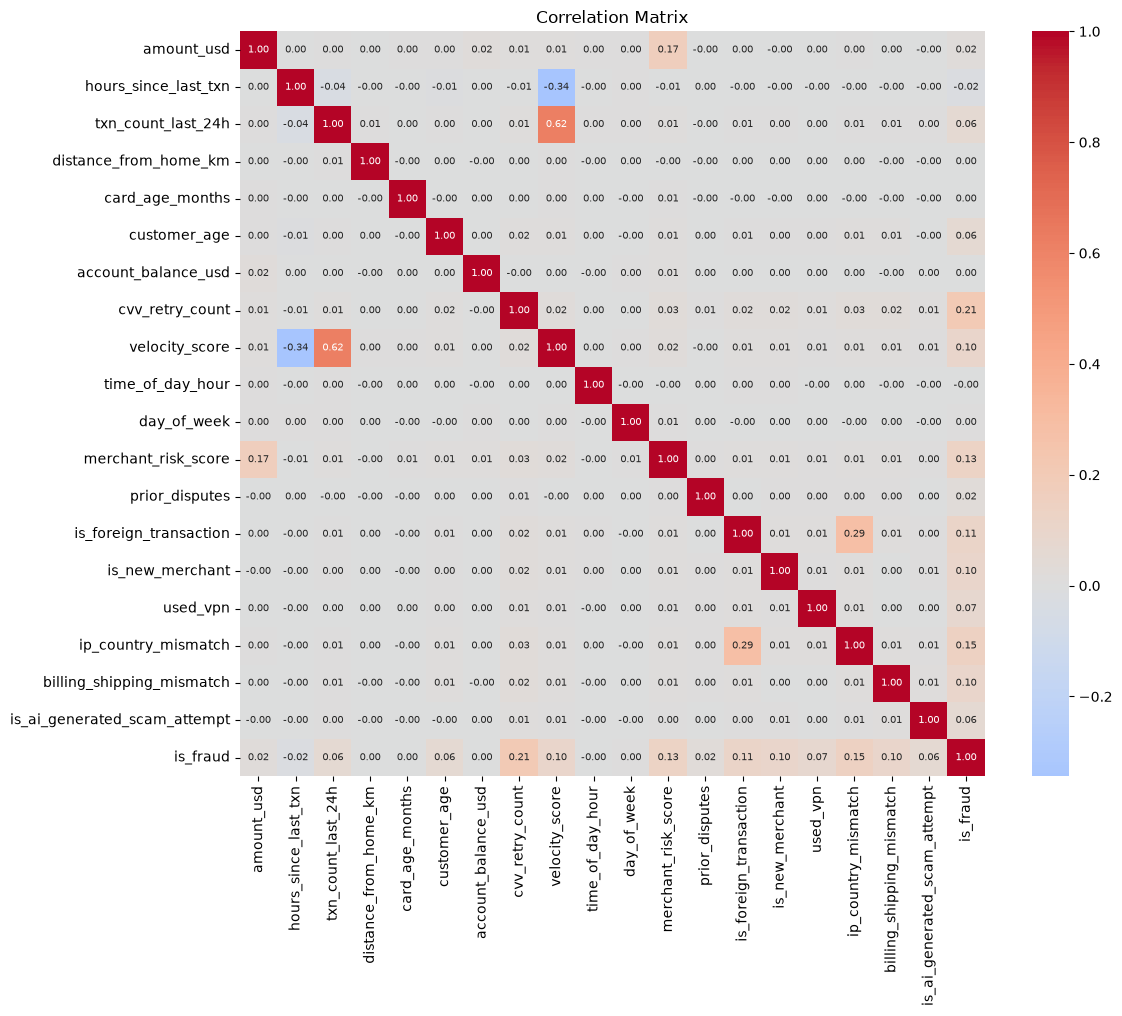

In [8]:
corr_df = train.copy()
for col in bool_cols:
    corr_df[col] = corr_df[col].astype(int)

corr_features = num_cols + bool_cols + ["is_fraud"]
corr = corr_df[corr_features].corr()

display(
    corr["is_fraud"]
    .drop("is_fraud")
    .sort_values(key=np.abs, ascending=False)
    .to_frame("corr_with_is_fraud")
)

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7},
    square=True,
    ax=ax,
)
ax.set_title("Correlation Matrix")
plt.tight_layout()
plt.show()

## Feature Engineering


In [9]:
def add_digit_features(df, cols):
    out = df.copy()
    for col in cols:
        vals = out[col].astype(float)
        out[f"{col}_frac"] = vals - np.floor(vals)
        out[f"{col}_int"] = np.floor(vals).astype(np.int32)
        abs_vals = np.maximum(np.abs(vals), 1e-12)
        out[f"{col}_lead"] = (abs_vals / np.power(10, np.floor(np.log10(abs_vals)))).astype(np.int8)
        dig_sum = np.zeros(len(out), dtype=np.int16)
        for k in range(1, 8):
            dig = ((vals * (10 ** k)) % 10).astype(np.int8)
            out[f"{col}_dig{k}"] = dig
            dig_sum = dig_sum + dig
        out[f"{col}_digsum"] = dig_sum
        out[f"{col}_pair12"] = out[f"{col}_dig1"] * 10 + out[f"{col}_dig2"]
        out[f"{col}_pair23"] = out[f"{col}_dig2"] * 10 + out[f"{col}_dig3"]
        out[f"{col}_id1"] = np.round(vals * 10).astype(np.int32)
        out[f"{col}_id2"] = np.round(vals * 100).astype(np.int32)
        for k in range(0, 5):
            out[f"{col}_round{k}"] = vals.round(k)
    return out

def add_frequency_features(train_df, test_df, cols):
    tr = train_df.copy()
    te = test_df.copy()
    for col in cols:
        freq_tr = train_df[col].value_counts()
        freq_all = pd.concat([train_df[col], test_df[col]], axis=0).value_counts()
        tr[f"{col}_freq"] = train_df[col].map(freq_tr).astype(np.float32)
        te[f"{col}_freq"] = test_df[col].map(freq_tr).fillna(1).astype(np.float32)
        tr[f"{col}_freq_all"] = train_df[col].map(freq_all).astype(np.float32)
        te[f"{col}_freq_all"] = test_df[col].map(freq_all).astype(np.float32)
        tr[f"{col}_rare"] = (tr[f"{col}_freq"] <= 5).astype(np.int8)
        te[f"{col}_rare"] = (te[f"{col}_freq"] <= 5).astype(np.int8)
    return tr, te

def encode_base(df, cat_maps=None):
    out = df.drop(columns=["id", "is_fraud"], errors="ignore").copy()
    for col in bool_cols:
        out[col] = out[col].astype(np.int8)
    maps = {}
    for col in cat_cols:
        if cat_maps is None:
            cats = sorted(out[col].astype(str).unique())
            maps[col] = {v: i for i, v in enumerate(cats)}
        else:
            maps[col] = cat_maps[col]
        out[col] = out[col].astype(str).map(maps[col]).fillna(-1).astype(np.int16)
    return out, maps

def add_oof_target_encoding(train_df, test_df, y_arr, cols, n_splits=5, smooth=20, seed=42):
    tr = train_df.copy()
    te = test_df.copy()
    global_mean = float(y_arr.mean())
    skf_te = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    for col in cols:
        tr[f"{col}_te"] = global_mean
        for tr_idx, va_idx in skf_te.split(train_df, y_arr):
            yt = y_arr[tr_idx]
            stats = (
                pd.DataFrame({"y": yt, "v": train_df.iloc[tr_idx][col].values})
                .groupby("v")["y"]
                .agg(["mean", "count"])
            )
            mapping = (
                (stats["mean"] * stats["count"] + global_mean * smooth) / (stats["count"] + smooth)
            ).to_dict()
            tr.iloc[va_idx, tr.columns.get_loc(f"{col}_te")] = (
                train_df.iloc[va_idx][col].map(mapping).fillna(global_mean).astype(np.float32).values
            )
        stats = (
            pd.DataFrame({"y": y_arr, "v": train_df[col].values})
            .groupby("v")["y"]
            .agg(["mean", "count"])
        )
        mapping = (
            (stats["mean"] * stats["count"] + global_mean * smooth) / (stats["count"] + smooth)
        ).to_dict()
        te[f"{col}_te"] = test_df[col].map(mapping).fillna(global_mean).astype(np.float32)
    return tr, te

X_raw, cat_maps = encode_base(train)
X_test_raw, _ = encode_base(test, cat_maps=cat_maps)
X_raw = add_digit_features(X_raw, digit_num_cols)
X_test_raw = add_digit_features(X_test_raw, digit_num_cols)
X_raw, X_test_raw = add_frequency_features(X_raw, X_test_raw, digit_num_cols)

te_cols = (
    cat_cols
    + [f"{c}_id2" for c in digit_num_cols]
    + [f"{c}_pair12" for c in digit_num_cols]
    + [f"{c}_lead" for c in digit_num_cols]
)
X, X_test = add_oof_target_encoding(X_raw, X_test_raw, y.values, te_cols, smooth=20, seed=42)

feature_cols = [c for c in X.columns if c in X_test.columns]
X = X[feature_cols].copy()
X_test = X_test[feature_cols].copy()

display(pd.Series({
    "n_features": len(feature_cols),
    "n_te_cols": len(te_cols),
    "n_lead_te": sum(c.endswith("_lead") for c in te_cols),
}))
display(X.head())

C:\Users\sshuser\AppData\Local\Temp\ipykernel_28224\3277105857.py:20: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{col}_round{k}"] = vals.round(k)
C:\Users\sshuser\AppData\Local\Temp\ipykernel_28224\3277105857.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{col}_frac"] = vals - np.floor(vals)
C:\Users\sshuser\AppData\Local\Temp\ipykernel_28224\3277105857.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consi

n_features    185
n_te_cols      23
n_lead_te       6
dtype: int64

,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,...,distance_from_home_km_pair12_te,account_balance_usd_pair12_te,velocity_score_pair12_te,merchant_risk_score_pair12_te,amount_usd_lead_te,hours_since_last_txn_lead_te,distance_from_home_km_lead_te,account_balance_usd_lead_te,velocity_score_lead_te,merchant_risk_score_lead_te
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,...,0.018332,0.014349,0.016953,0.016682,0.017381,0.017712,0.016362,0.016865,0.023147,0.004736
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,...,0.017064,0.019653,0.020402,0.019180,0.014849,0.016783,0.016251,0.017516,0.033889,0.005103
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,...,0.015487,0.018676,0.037076,0.014452,0.017397,0.016783,0.016632,0.016854,0.033889,0.005103
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,...,0.018306,0.014320,0.017750,0.019180,0.013716,0.015827,0.016632,0.015467,0.018409,0.024778
4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,...,0.012945,0.020808,0.037624,0.017826,0.017580,0.015424,0.016308,0.017593,0.033191,0.024995


## Model

In [10]:
def fit_lgb(X_tr, y_tr, X_va, y_va, seed, num_leaves, max_depth, lr, n_estimators=10000, stop=250):
    model = lgb.LGBMClassifier(
        objective="binary",
        metric="auc",
        learning_rate=lr,
        num_leaves=num_leaves,
        max_depth=max_depth,
        min_child_samples=20,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=0.0,
        reg_alpha=0.0,
        n_estimators=n_estimators,
        random_state=seed,
        n_jobs=4,
        verbose=-1,
    )
    model.fit(
        X_tr[feature_cols],
        y_tr,
        eval_X=X_va[feature_cols],
        eval_y=y_va,
        callbacks=[lgb.early_stopping(stop, verbose=False)],
    )
    return model

def make_key_frame(df):
    parts = {}
    for col in digit_num_cols:
        parts[f"v_{col}"] = col + "=" + df[col].astype(str)
        parts[f"id2_{col}"] = f"{col}_id2=" + df[f"{col}_id2"].astype(str)
        parts[f"p12_{col}"] = f"{col}_pair12=" + df[f"{col}_pair12"].astype(str)
        parts[f"lead_{col}"] = f"{col}_lead=" + df[f"{col}_lead"].astype(str)
        for k in range(1, 5):
            parts[f"d{k}_{col}"] = f"{col}_dig{k}=" + df[f"{col}_dig{k}"].astype(str)
    for col in cat_cols:
        parts[f"c_{col}"] = col + "=" + df[col].astype(str)
    return pd.DataFrame(parts)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_preds = {}
test_preds = {}
train_key_df = make_key_frame(X)
test_key_df = make_key_frame(X_test)
te_logit_cols = [f"{c}_te" for c in te_cols]
print("key cols", train_key_df.shape[1])

key cols 53


In [11]:
lgb4_seeds = [42, 7, 99, 123]
oof_lgb4_bag = np.zeros(len(X))
pred_lgb4_bag = np.zeros(len(X_test))

for seed in lgb4_seeds:
    oof_seed = np.zeros(len(X))
    pred_seed = np.zeros(len(X_test))
    for fold, (tr_idx, va_idx) in enumerate(skf.split(X, y), start=1):
        X_tr, y_tr = X.iloc[tr_idx], y.iloc[tr_idx]
        X_va, y_va = X.iloc[va_idx], y.iloc[va_idx]
        model = fit_lgb(X_tr, y_tr, X_va, y_va, seed=seed + fold, num_leaves=4, max_depth=3, lr=0.02)
        oof_seed[va_idx] = model.predict_proba(X_va[feature_cols])[:, 1]
        pred_seed += model.predict_proba(X_test[feature_cols])[:, 1] / skf.n_splits
        print(f"lgb4 seed {seed} fold {fold}: {roc_auc_score(y_va, oof_seed[va_idx]):.6f} iter={model.best_iteration_}")
    print(f"lgb4 seed {seed} cv: {roc_auc_score(y, oof_seed):.6f}")
    oof_lgb4_bag += oof_seed / len(lgb4_seeds)
    pred_lgb4_bag += pred_seed / len(lgb4_seeds)

print(f"lgb4 bag cv: {roc_auc_score(y, oof_lgb4_bag):.6f}")
oof_preds["lgb4_bag"] = oof_lgb4_bag
test_preds["lgb4_bag"] = pred_lgb4_bag

lgb4 seed 42 fold 1: 0.947781 iter=3979
lgb4 seed 42 fold 2: 0.949940 iter=3770
lgb4 seed 42 fold 3: 0.954117 iter=3714
lgb4 seed 42 fold 4: 0.950109 iter=3739
lgb4 seed 42 fold 5: 0.943989 iter=3944
lgb4 seed 42 cv: 0.949170
lgb4 seed 7 fold 1: 0.947910 iter=3871
lgb4 seed 7 fold 2: 0.949892 iter=2851
lgb4 seed 7 fold 3: 0.954304 iter=4088
lgb4 seed 7 fold 4: 0.950074 iter=3134
lgb4 seed 7 fold 5: 0.943885 iter=4759
lgb4 seed 7 cv: 0.949174
lgb4 seed 99 fold 1: 0.948018 iter=4081
lgb4 seed 99 fold 2: 0.949792 iter=3226
lgb4 seed 99 fold 3: 0.954342 iter=3727
lgb4 seed 99 fold 4: 0.950216 iter=3669
lgb4 seed 99 fold 5: 0.943676 iter=3517
lgb4 seed 99 cv: 0.949182
lgb4 seed 123 fold 1: 0.947805 iter=4134
lgb4 seed 123 fold 2: 0.949968 iter=3570
lgb4 seed 123 fold 3: 0.954442 iter=5931
lgb4 seed 123 fold 4: 0.950250 iter=3174
lgb4 seed 123 fold 5: 0.944304 iter=5710
lgb4 seed 123 cv: 0.949325
lgb4 bag cv: 0.949281


In [12]:
oof_lgb3 = np.zeros(len(X))
pred_lgb3 = np.zeros(len(X_test))

for fold, (tr_idx, va_idx) in enumerate(skf.split(X, y), start=1):
    X_tr, y_tr = X.iloc[tr_idx], y.iloc[tr_idx]
    X_va, y_va = X.iloc[va_idx], y.iloc[va_idx]
    model = fit_lgb(X_tr, y_tr, X_va, y_va, seed=100 + fold, num_leaves=3, max_depth=2, lr=0.015, stop=300)
    oof_lgb3[va_idx] = model.predict_proba(X_va[feature_cols])[:, 1]
    pred_lgb3 += model.predict_proba(X_test[feature_cols])[:, 1] / skf.n_splits
    print(f"lgb3 fold {fold}: {roc_auc_score(y_va, oof_lgb3[va_idx]):.6f} iter={model.best_iteration_}")

print(f"lgb3 cv: {roc_auc_score(y, oof_lgb3):.6f}")
oof_preds["lgb3"] = oof_lgb3
test_preds["lgb3"] = pred_lgb3

lgb3 fold 1: 0.947895 iter=7720
lgb3 fold 2: 0.949938 iter=7347
lgb3 fold 3: 0.954529 iter=7566
lgb3 fold 4: 0.950419 iter=8890
lgb3 fold 5: 0.944210 iter=7532
lgb3 cv: 0.949389


In [13]:
oof_lgb7 = np.zeros(len(X))
pred_lgb7 = np.zeros(len(X_test))

for fold, (tr_idx, va_idx) in enumerate(skf.split(X, y), start=1):
    X_tr, y_tr = X.iloc[tr_idx], y.iloc[tr_idx]
    X_va, y_va = X.iloc[va_idx], y.iloc[va_idx]
    model = fit_lgb(X_tr, y_tr, X_va, y_va, seed=200 + fold, num_leaves=7, max_depth=4, lr=0.02)
    oof_lgb7[va_idx] = model.predict_proba(X_va[feature_cols])[:, 1]
    pred_lgb7 += model.predict_proba(X_test[feature_cols])[:, 1] / skf.n_splits
    print(f"lgb7 fold {fold}: {roc_auc_score(y_va, oof_lgb7[va_idx]):.6f} iter={model.best_iteration_}")

print(f"lgb7 cv: {roc_auc_score(y, oof_lgb7):.6f}")
oof_preds["lgb7"] = oof_lgb7
test_preds["lgb7"] = pred_lgb7

lgb7 fold 1: 0.947795 iter=2821
lgb7 fold 2: 0.949702 iter=2021
lgb7 fold 3: 0.954147 iter=3769
lgb7 fold 4: 0.950003 iter=3385
lgb7 fold 5: 0.943512 iter=2828
lgb7 cv: 0.949010


In [14]:
oof_xgb = np.zeros(len(X))
pred_xgb = np.zeros(len(X_test))

for fold, (tr_idx, va_idx) in enumerate(skf.split(X, y), start=1):
    X_tr, y_tr = X.iloc[tr_idx], y.iloc[tr_idx]
    X_va, y_va = X.iloc[va_idx], y.iloc[va_idx]
    model = XGBClassifier(
        n_estimators=6000,
        learning_rate=0.02,
        max_depth=3,
        min_child_weight=10,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        eval_metric="auc",
        early_stopping_rounds=200,
        random_state=42 + fold,
        n_jobs=4,
        tree_method="hist",
    )
    model.fit(
        X_tr[feature_cols],
        y_tr,
        eval_set=[(X_va[feature_cols], y_va)],
        verbose=False,
    )
    oof_xgb[va_idx] = model.predict_proba(X_va[feature_cols])[:, 1]
    pred_xgb += model.predict_proba(X_test[feature_cols])[:, 1] / skf.n_splits
    print(f"xgb3 fold {fold}: {roc_auc_score(y_va, oof_xgb[va_idx]):.6f}")

print(f"xgb3 cv: {roc_auc_score(y, oof_xgb):.6f}")
oof_preds["xgb3"] = oof_xgb
test_preds["xgb3"] = pred_xgb

xgb3 fold 1: 0.947337
xgb3 fold 2: 0.949513
xgb3 fold 3: 0.945821
xgb3 fold 4: 0.949556
xgb3 fold 5: 0.942877
xgb3 cv: 0.946745


In [15]:
oof_cat = np.zeros(len(X))
pred_cat = np.zeros(len(X_test))

for fold, (tr_idx, va_idx) in enumerate(skf.split(X, y), start=1):
    X_tr, y_tr = X.iloc[tr_idx], y.iloc[tr_idx]
    X_va, y_va = X.iloc[va_idx], y.iloc[va_idx]
    model = CatBoostClassifier(
        loss_function="Logloss",
        eval_metric="AUC",
        learning_rate=0.03,
        depth=3,
        l2_leaf_reg=3.0,
        iterations=6000,
        random_seed=42 + fold,
        verbose=False,
        early_stopping_rounds=150,
    )
    model.fit(
        Pool(X_tr[feature_cols], y_tr),
        eval_set=Pool(X_va[feature_cols], y_va),
        use_best_model=True,
    )
    oof_cat[va_idx] = model.predict_proba(X_va[feature_cols])[:, 1]
    pred_cat += model.predict_proba(X_test[feature_cols])[:, 1] / skf.n_splits
    print(f"cat3 fold {fold}: {roc_auc_score(y_va, oof_cat[va_idx]):.6f} iter={model.get_best_iteration()}")

print(f"cat3 cv: {roc_auc_score(y, oof_cat):.6f}")
oof_preds["cat3"] = oof_cat
test_preds["cat3"] = pred_cat

cat3 fold 1: 0.947101 iter=4172
cat3 fold 2: 0.949298 iter=3471
cat3 fold 3: 0.953877 iter=2998
cat3 fold 4: 0.949042 iter=4170
cat3 fold 5: 0.944148 iter=5958
cat3 cv: 0.948614


In [16]:
oof_glm = np.zeros(len(X))
pred_glm = np.zeros(len(X_test))

for fold, (tr_idx, va_idx) in enumerate(skf.split(X, y), start=1):
    enc = OneHotEncoder(handle_unknown="ignore", min_frequency=20, sparse_output=True)
    X_tr_oh = enc.fit_transform(train_key_df.iloc[tr_idx])
    X_va_oh = enc.transform(train_key_df.iloc[va_idx])
    X_te_oh = enc.transform(test_key_df)

    X_tr_m = sp.hstack([X_tr_oh, sp.csr_matrix(X.iloc[tr_idx][te_logit_cols].to_numpy(dtype=np.float32))]).tocsr()
    X_va_m = sp.hstack([X_va_oh, sp.csr_matrix(X.iloc[va_idx][te_logit_cols].to_numpy(dtype=np.float32))]).tocsr()
    X_te_m = sp.hstack([X_te_oh, sp.csr_matrix(X_test[te_logit_cols].to_numpy(dtype=np.float32))]).tocsr()

    model = LogisticRegression(
        C=0.1,
        penalty="l2",
        solver="saga",
        max_iter=1500,
        n_jobs=4,
        random_state=42 + fold,
    )
    model.fit(X_tr_m, y.iloc[tr_idx])
    oof_glm[va_idx] = model.predict_proba(X_va_m)[:, 1]
    pred_glm += model.predict_proba(X_te_m)[:, 1] / skf.n_splits
    print(f"glm fold {fold}: {roc_auc_score(y.iloc[va_idx], oof_glm[va_idx]):.6f} n_features={X_tr_m.shape[1]}")

print(f"glm cv: {roc_auc_score(y, oof_glm):.6f}")
oof_preds["glm_ohk"] = oof_glm
test_preds["glm_ohk"] = pred_glm

C:\Users\sshuser\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\sshuser\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=4', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


glm fold 1: 0.857312 n_features=34604


C:\Users\sshuser\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\sshuser\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=4', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


glm fold 2: 0.850251 n_features=34606


C:\Users\sshuser\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\sshuser\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=4', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


glm fold 3: 0.858453 n_features=34594


C:\Users\sshuser\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\sshuser\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=4', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


glm fold 4: 0.856699 n_features=34620


C:\Users\sshuser\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\sshuser\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=4', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


glm fold 5: 0.845492 n_features=34658
glm cv: 0.853614


In [17]:
member_names = list(oof_preds.keys())
for name in member_names:
    print(f"{name}: {roc_auc_score(y, oof_preds[name]):.6f}")

oof_matrix = np.column_stack([oof_preds[k] for k in member_names])
test_matrix = np.column_stack([test_preds[k] for k in member_names])

oof_logit = np.zeros(len(X))
test_logit = np.zeros(len(X_test))
for fold, (tr_idx, va_idx) in enumerate(skf.split(oof_matrix, y), start=1):
    meta = LogisticRegression(C=1.0, max_iter=2000, solver="lbfgs")
    meta.fit(oof_matrix[tr_idx], y.iloc[tr_idx])
    oof_logit[va_idx] = meta.predict_proba(oof_matrix[va_idx])[:, 1]
    test_logit += meta.predict_proba(test_matrix)[:, 1] / skf.n_splits
    print(f"logit stack fold {fold}: {roc_auc_score(y.iloc[va_idx], oof_logit[va_idx]):.6f}")
print(f"logit stack cv: {roc_auc_score(y, oof_logit):.6f}")

eps = 1e-6
p = 0.5
oof_pow = np.mean([np.clip(oof_preds[k], eps, 1 - eps) ** p for k in member_names], axis=0) ** (1 / p)
test_pow = np.mean([np.clip(test_preds[k], eps, 1 - eps) ** p for k in member_names], axis=0) ** (1 / p)
print(f"power-mean p={p} cv: {roc_auc_score(y, oof_pow):.6f}")

def hill_climb(oof_dict, y_arr, max_models=8):
    remaining = dict(oof_dict)
    start = max(remaining, key=lambda k: roc_auc_score(y_arr, remaining[k]))
    blend = remaining.pop(start).astype(np.float64).copy()
    weights = {start: 1.0}
    best_auc = roc_auc_score(y_arr, blend)
    print(f"hill start {start}: {best_auc:.6f}")
    improved = True
    while improved and remaining and len(weights) < max_models:
        improved = False
        best_step = None
        for name, pred in remaining.items():
            for w in np.linspace(0.05, 0.5, 10):
                trial = (1 - w) * blend + w * pred
                auc = roc_auc_score(y_arr, trial)
                if auc > best_auc + 1e-6:
                    best_auc = auc
                    best_step = (name, w, trial)
                    improved = True
        if best_step is not None:
            name, w, trial = best_step
            for k in weights:
                weights[k] *= (1 - w)
            weights[name] = weights.get(name, 0.0) + w
            blend = trial
            remaining.pop(name)
            print(f"hill add {name} w={w:.2f}: {best_auc:.6f}")
    return blend, weights, best_auc

oof_hill, hill_weights, hill_auc = hill_climb(oof_preds, y)
test_hill = np.zeros(len(X_test))
for name, w in hill_weights.items():
    test_hill += w * test_preds[name]
print(f"hill cv: {hill_auc:.6f}")
print("hill weights:", {k: round(v, 4) for k, v in hill_weights.items()})

candidates = {
    "logit": (roc_auc_score(y, oof_logit), test_logit),
    "power_mean": (roc_auc_score(y, oof_pow), test_pow),
    "hill": (hill_auc, test_hill),
}
best_name = max(candidates, key=lambda k: candidates[k][0])
cv_auc, test_pred = candidates[best_name]
print(f"selected {best_name} cv={cv_auc:.6f}")

submission = sample_submission.copy()
submission["is_fraud"] = test_pred
submission.to_csv("submission.csv", index=False)
display(submission.head())
print(cv_auc)

lgb4_bag: 0.949281
lgb3: 0.949389
lgb7: 0.949010
xgb3: 0.946745
cat3: 0.948614
glm_ohk: 0.853614
logit stack fold 1: 0.943379
logit stack fold 2: 0.943978
logit stack fold 3: 0.950592
logit stack fold 4: 0.944589
logit stack fold 5: 0.939020
logit stack cv: 0.943536
power-mean p=0.5 cv: 0.948265
hill start lgb3: 0.949389
hill add lgb7 w=0.25: 0.949446
hill add cat3 w=0.15: 0.949470
hill cv: 0.949470
hill weights: {'lgb3': np.float64(0.6375), 'lgb7': np.float64(0.2125), 'cat3': np.float64(0.15)}
selected hill cv=0.949470


,id,is_fraud
0,699960,0.000221
1,699961,0.000206
2,699962,0.076905
3,699963,0.001750
4,699964,0.001220


0.9494696178840754
